# Construisons un module de géométrie (1/2)

Les deux prochains TPs seront consacrés à la création d'un module pour gérer la géométrie. L'objectif est d'apprendre à fabriquer un module avec des objets (création de classes) qui vont dépendre les uns des autres.

Pour commencer, nous allons travailler dans un notebook et créer deux objets géométriques : le disque et le polygone. Lors du prochain TP, nous créerons réellement le module.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
mpl.rcParams['savefig.dpi'] = 80

## La classe `disque`

Commençons par créer une classe `disque` qui va nous permettre de manipuler des disques en connaissant leur centre et leur rayon. L'objectif est ici simplement de manipuler une nouvelle classe.

**Question 1**

> 1. Créez une classe `disque` dont on pourra initialiser une nouvelle instance en donnant en argument de la fonction `__init__` le centre `c`, le rayon `r` et son nom `nom`. Vous veillerez à ce que
>   - `c` puisse être une `list` ou un `ndarray` contenant des `float`;
>   - `c` soit de taille 2 ;
>   - `r` soit un réel (ou un entier) strictement positif ;
>   - `nom` puisse ne pas être renseigné et vaudra par défaut `"D"`.
> 2. Un objet de la classe `disque` aura alors 3 attributs :
>   - `_c` un `ndarray` de taille 2 contenant le centre du disque ;
>   - `_r` un `float` contenant le rayon du disque ;
>   - `_name` une chaîne de caractères contenant le nom du disque.
> 3. Vérifiez que votre classe fonctionne pour le moment...

In [2]:
class DimensionError(Exception):
    def __init__(self, val):
        self.val = val

    def __str__(self):
        return f"La dimension doit être 2 : elle vaut {self.val}"


def listorarray_to_array(in_l, name):
    if not isinstance(in_l, (list, np.ndarray)):
        raise TypeError(f"{name} doit être une liste ou un ndarray")
    in_l = np.array(in_l, copy=True, dtype=float)
    if in_l.shape[0] != 2:
        raise DimensionError(in_l.shape[0])
    return in_l


class disque():
    """
    Une classe pour les disques

    Parameters
    ----------

    c: ndarray de taille 2
        le centre du disque
    r: float strictement positif
        le rayon du disque
    """
    def __init__(self, c, r, nom="D"):
        self._c = listorarray_to_array(c, "Le centre")
        if not isinstance(r, (int, float)):
            raise TypeError("Le rayon doit être un réel")
        if r <= 0:
            raise ValueError("Le rayon doit être strictement positif")
        self._r = r
        self._name = nom
        

D = disque([0, 0], 1, "D")
print(D._c, D._r, D._name)

# D = disque(1, [0, 0])
# D = disque([0, 0, 0], 1)

[0. 0.] 1 D


**Question 2**

> 1. Ajoutez une fonction membre `centre` qui retourne le `ndarray` `_c`. Décorez cette fonction avec le décorateur `@property` (attention, la classe `disque` doit pour cela hériter de la classe `object`) afin que la fonction devienne un attribut accessible seulement en lecture.
> 2. Ajoutez de la même façon un attribut en lecture seule `rayon` qui renvoie le rayon du disque.

In [17]:
class disque():
    """
    Une classe pour les disques

    Parameters
    ----------

    c: ndarray de taille 2
        le centre du disque
    r: float strictement positif
        le rayon du disque
    """
    def __init__(self, c, r, nom="D"):
        self._c = listorarray_to_array(c, "Le centre")
        if not isinstance(r, (int, float)):
            raise TypeError("Le rayon doit être un réel")
        if r <= 0:
            raise ValueError("Le rayon doit être strictement positif")
        self._r = r
        self._name = nom
        
    @property
    def centre(self):
        return self._c
    
    @property
    def rayon(self):
        return self._r

    
D = disque([0, 0], 1, "D")
print(D.centre, D.rayon)

[0. 0.] 1


**Question 3**

> Ajoutez trois attributs en lecture seule (fonction décorée avec `@property`) qui retourne le périmètre, l'aire et le centre de gravité du disque.

*Indication : la valeur $\pi$ pourrait être un nombre partagé par toutes les instances de la classe `disque`*

In [19]:
class disque():
    """
    Une classe pour les disques

    Parameters
    ----------

    c: ndarray de taille 2
        le centre du disque
    r: float strictement positif
        le rayon du disque
    """
    pi = np.pi
    
    def __init__(self, c, r, nom="D"):
        self._c = listorarray_to_array(c, "Le centre")
        if not isinstance(r, (int, float)):
            raise TypeError("Le rayon doit être un réel")
        if r <= 0:
            raise ValueError("Le rayon doit être strictement positif")
        self._r = r
        self._name = nom
        
    @property
    def centre(self):
        return self._c
    
    @property
    def rayon(self):
        return self._r
    
    @property
    def perimetre(self):
        return 2*self.pi*self._r

    @property
    def aire(self):
        return self.pi*self._r*self._r

    @property
    def gravity(self):
        return self._c

    
D = disque([0, 0], 1, "D")
print(D.centre, D.rayon)
print(D.perimetre, D.aire, D.gravity)

[0. 0.] 1
6.283185307179586 3.141592653589793 [0. 0.]


**Question 4**

> Ajoutez un attribut en lecture seule (une fonction décorée avec `@property`) qui est un dictionnaire de la forme
> ```python
> {
>   'x': [xmin, xmax],
>   'y': [ymin, ymax],
> }
> ```
> où `xmin` et `xmax` sont une borne inférieure et une borne supérieure des abscisses des points du disque et `ymin` et `ymax` des ordonnées.

In [20]:
class disque():
    """
    Une classe pour les disques

    Parameters
    ----------

    c: ndarray de taille 2
        le centre du disque
    r: float strictement positif
        le rayon du disque
    """
    pi = np.pi
    
    def __init__(self, c, r, nom="D"):
        self._c = listorarray_to_array(c, "Le centre")
        if not isinstance(r, (int, float)):
            raise TypeError("Le rayon doit être un réel")
        if r <= 0:
            raise ValueError("Le rayon doit être strictement positif")
        self._r = r
        self._name = nom
        
    @property
    def centre(self):
        return self._c
    
    @property
    def rayon(self):
        return self._r
    
    @property
    def perimetre(self):
        return 2*self.pi*self._r

    @property
    def aire(self):
        return self.pi*self._r*self._r

    @property
    def gravity(self):
        return self._c
    
    @property
    def box(self):
        return {
            'x': [self._c[0]-self._r, self._c[0]+self._r],
            'y': [self._c[1]-self._r, self._c[1]+self._r],
        }

    
D = disque([0, 0], 1, "D")
print(D.centre, D.rayon)
print(D.perimetre, D.aire, D.gravity)
print(D.box)

[0. 0.] 1
6.283185307179586 3.141592653589793 [0. 0.]
{'x': [-1.0, 1.0], 'y': [-1.0, 1.0]}


**Question 5**

> Ajoutez une fonction membre `info` qui retourne une chaine de caractères contenant les informations du disque en respectant ce format
> ```
> ---------------------------------------------------------------
> Disque D de centre [0. 0.] et de rayon 1
>     Le périmètre de D vaut        6.283185307179586
>     L'aire de D vaut              3.141592653589793
>     Le centre de gravité de D est [0. 0.]
> ---------------------------------------------------------------
> ```


In [22]:
class disque():
    """
    Une classe pour les disques

    Parameters
    ----------

    c: ndarray de taille 2
        le centre du disque
    r: float strictement positif
        le rayon du disque
    """
    pi = np.pi
    
    def __init__(self, c, r, nom="D"):
        self._c = listorarray_to_array(c, "Le centre")
        if not isinstance(r, (int, float)):
            raise TypeError("Le rayon doit être un réel")
        if r <= 0:
            raise ValueError("Le rayon doit être strictement positif")
        self._r = r
        self._name = nom
        
    @property
    def centre(self):
        return self._c
    
    @property
    def rayon(self):
        return self._r
    
    @property
    def perimetre(self):
        return 2*self.pi*self._r

    @property
    def aire(self):
        return self.pi*self._r*self._r

    @property
    def gravity(self):
        return self._c
    
    @property
    def box(self):
        return {
            'x': [self._c[0]-self._r, self._c[0]+self._r],
            'y': [self._c[1]-self._r, self._c[1]+self._r],
        }
    
    def __str__(self):
        return f"{self._name}"
    
    def info(self):
        s = "-"*80
        s += "\n"
        s += f"Disque {self._name} de centre {self._c} et de rayon {self._r}\n"
        s += f"    Le périmètre de {self} vaut        {self.perimetre}\n"
        s += f"    L'aire de {self} vaut              {self.aire}\n"
        s += f"    Le centre de gravité de {self} est {self.gravity}\n"
        s += "-"*80
        s += "\n"
        return s

    
D = disque([0, 0], 1, "D")
print(D.info())

--------------------------------------------------------------------------------
Disque D de centre [0. 0.] et de rayon 1
    Le périmètre de D vaut        6.283185307179586
    L'aire de D vaut              3.141592653589793
    Le centre de gravité de D est [0. 0.]
--------------------------------------------------------------------------------



**Question 6**

> 1. Ajoutez une fonction membre `_is_in` qui prend en arguments deux `ndarray` (notés `x` et `y`) de même forme et qui retourne un `ndarray` de booléens de la même forme dont les valeurs sont `True` ou `False` selon que le point appartient ou non au disque.
> 2. Ajoutez une fonction membre `visualize` qui prend en arguments un axe `ax` de la classe `matplotlib.axes._subplots.AxesSubplot` et qui affiche un nuage de points équi-répartis à l'intérieur du disque. Vous pourrez essayer de reproduire cette figure obtenue pour le cercle de centre $(0, 0)$ et de rayon 1 :
![cercle](cercle.png)

--------------------------------------------------------------------------------
Disque D de centre [0. 0.] et de rayon 1
    Le périmètre de D vaut        6.283185307179586
    L'aire de D vaut              3.141592653589793
    Le centre de gravité de D est [0. 0.]
--------------------------------------------------------------------------------

Help on class disque in module __main__:

class disque(builtins.object)
 |  disque(c, r, nom='D')
 |  
 |  Une classe pour les disques
 |  
 |  Parameters
 |  ----------
 |  
 |  c: ndarray de taille 2
 |      le centre du disque
 |  r: float strictement positif
 |      le rayon du disque
 |      
 |  Attributs
 |  ---------
 |  
 |  centre: ...
 |  
 |  Methods defined here:
 |  
 |  __init__(self, c, r, nom='D')
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  __str__(self)
 |      Return str(self).
 |  
 |  info(self)
 |  
 |  visualize(self, ax)
 |  
 |  ------------------------------------------------------

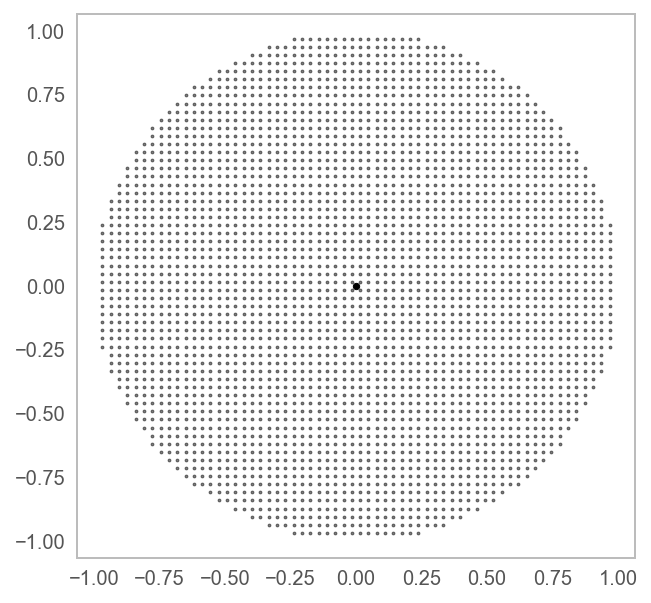

In [7]:
class disque:
    """
    Une classe pour les disques

    Parameters
    ----------

    c: ndarray de taille 2
        le centre du disque
    r: float strictement positif
        le rayon du disque
        
    Attributs
    ---------
    
    centre: ...
    """
    pi = np.pi
    
    def __init__(self, c, r, nom="D"):
        self._c = listorarray_to_array(c, "Le centre")
        if not isinstance(r, (int, float)):
            raise TypeError("Le rayon doit être un réel")
        if r <= 0:
            raise ValueError("Le rayon doit être strictement positif")
        self._r = r
        self._name = nom
        
    @property
    def centre(self):
        """centre du disque"""
        return self._c
    
    @property
    def rayon(self):
        return self._r
    
    @property
    def perimetre(self):
        return 2*self.pi*self._r

    @property
    def aire(self):
        return self.pi*self._r*self._r

    @property
    def gravity(self):
        return self._c
    
    @property
    def box(self):
        return {
            'x': [self._c[0]-self._r, self._c[0]+self._r],
            'y': [self._c[1]-self._r, self._c[1]+self._r],
        }
    
    def __str__(self):
        return f"{self._name}"
    
    def info(self):
        s = "-"*80
        s += "\n"
        s += f"Disque {self._name} de centre {self._c} et de rayon {self._r}\n"
        s += f"    Le périmètre de {self} vaut        {self.perimetre}\n"
        s += f"    L'aire de {self} vaut              {self.aire}\n"
        s += f"    Le centre de gravité de {self} est {self.gravity}\n"
        s += "-"*80
        s += "\n"
        return s
    
    def _is_in(self, x, y):
        if x.shape != y.shape:
            print("Problème de dimension dans _is_in")
        return (x-self._c[0])**2 + (y-self._c[1])**2 <= self._r**2
    
    def visualize(self, ax):
        # nuage de points
        x = np.linspace(self.box['x'][0], self.box['x'][1], 64)
        y = np.linspace(self.box['y'][0], self.box['y'][1], 64)
        X, Y = np.meshgrid(x, y, indexing='xy')
        ind_in = self._is_in(X, Y)
        ax.scatter(X[ind_in], Y[ind_in], color='black', alpha=0.5, s=2)
        # centre de gravité
        ax.scatter(
            self.gravity[0], self.gravity[1],
            color='black', alpha=1, s=10
        )
        # modification des limites de la figure
        limx = ax.get_xlim()
        boxx = self.box['x']
        limy = ax.get_ylim()
        boxy = self.box['y']
        m = min(limx[0], boxx[0], limy[0], boxy[0])
        M = max(limx[1], boxx[1], limy[1], boxy[1])
        ax.set_xlim(m, M)
        ax.set_ylim(m, M)

    
D = disque([0, 0], 1, "D")
print(D.info())
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)
D.visualize(ax)
fig.savefig("cercle.png")

help(disque)

## Le module `geometrie`

**Question 7**

Nous allons commencer à construire le module `geometrie` avec la classe `disque` précédemment construite.

> 1. Créez un dossier `TP07_geometrie` dans le répertoire à côté du notebook.
> 2. Créez un fichier `__init__.py` dans ce dossier (ce sera le fichier d'initialisation du module).
> 3. Créez un fichier `disque.py` dans ce dossier et copier le code de la classe `disque` à l'intérieur.
> 4. Ajoutez dans le fichier `disque.py` les entêtes nécessaires, par exemple `import numpy as np`.
> 5. Ajoutez dans le fichier `__init__.py` la ligne
> ```python
> from .disque import disque
> ```

A présent, vous devez pour accéder à votre module nouvellement créé. Testez pour cela les lignes de code des cellules suivantes.

In [28]:
import TP07_geometrie as geom

--------------------------------------------------------------------------------
Disque D de centre [0. 0.] et de rayon 1
    Le périmètre de D vaut        6.283185307179586
    L'aire de D vaut              3.141592653589793
    Le centre de gravité de D est [0. 0.]
--------------------------------------------------------------------------------



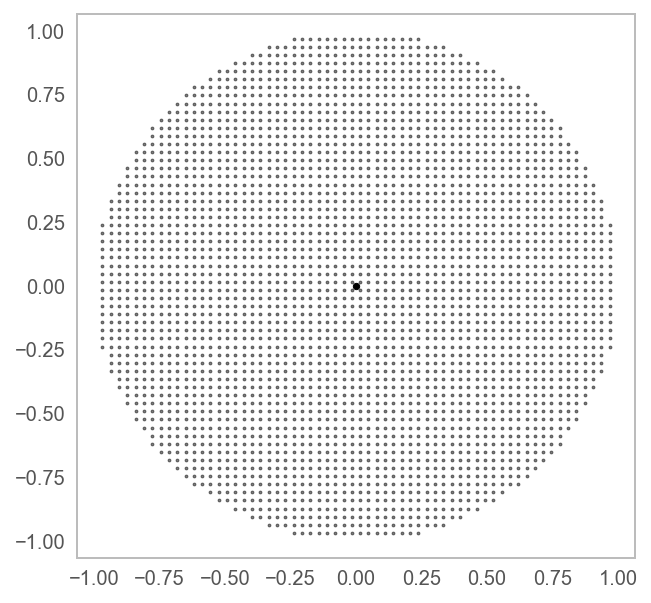

In [29]:
D = geom.disque([0, 0], 1, "D")
print(D.info())

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)
D.visualize(ax)

## Une deuxième classe : la classe `polygone`

Nous allons à présent ajouter un deuxième objet géométrie de type polygone. Un polygone sera défini par la liste de ses sommets (nous utiliserons un `ndarray` de forme $(p,2)$ où $p$ est le nombre de sommets pour les stocker).

*NB : pour simplifier les choses, nous supposerons dans la suite que tous les polygones que l'on construira seront convexes.*

Quelques rappels de géométrie sur les polygones convexes. Nous notons $s_0, \ldots, s_{p-1}$, les $p$ sommets de ce polygone. L'aire d'un tel polygone vaut
$$
A = \frac{1}{2} \sum_{k=1}^{p-2} (s_{k,x}-s_{0,x})(s_{k+1,y}-s_{0,y}) - (s_{k,y}-s_{0,y})(s_{k+1,x}-s_{0,x})
$$
Par ailleurs, pour déterminer si un point $P$ de coordonnées $(x, y)$ est dans un tel polygome, il faut calculer $\theta$ l'angle défini par
$$
\theta = \sum_{k=0}^{p-2} \widehat{s_k P s_{k+1}},
\quad\text{avec}\quad
\widehat{s_k P s_{k+1}} = \operatorname{arctan2} (\operatorname{det}, \operatorname{pscal})
$$
et
$$
\begin{aligned}
\operatorname{det} &= u_x v_y - u_y v_x,&
\operatorname{pscal} &= u_x v_x + u_y v_y,\\
u_x &= s_{k,x} - x,&
u_y &= s_{k,y} - y,\\
v_x &= s_{k+1,x} - x,&
v_y &= s_{k+1,y} - y.
\end{aligned}
$$
Si le point est dans le polygone, $\theta$ vaut $\pm 2\pi$. Sinon il vaut $0$.

**Question 8**

> Créez la classe `polygone` que vous mettrez dans un fichier `polygone.py` dans le même répertoire que `disque.py` en adaptant la classe `disque`. Pensez à ajouter la ligne 
> ```python
> from .polygone import polygone
> ```
> dans le fichier `__init__.py`.
>
> Testez ensuite cette nouvelle classe en créant et affichant un triangle et un carré de votre choix (vous pourrez aussi faire une figure avec plusieurs formes géométriques.
>
> *(Question bonus)* en utilisant `ax.get_xlim` et `ax.get_ylim`, récupérez et modifiez les bornes du graphique afin que les figures affichent bien tous les objets géométriques que vous voulez.

--------------------------------------------------------------------------------
Polygone P a 3 points
    Les points sont
    [0. 0.] [0. 1.] [1. 0.] 
    Le périmètre de P vaut        3.414213562373095
    L'aire de P vaut              0.5
    Le centre de gravité de P est [0.33333333 0.33333333]
--------------------------------------------------------------------------------



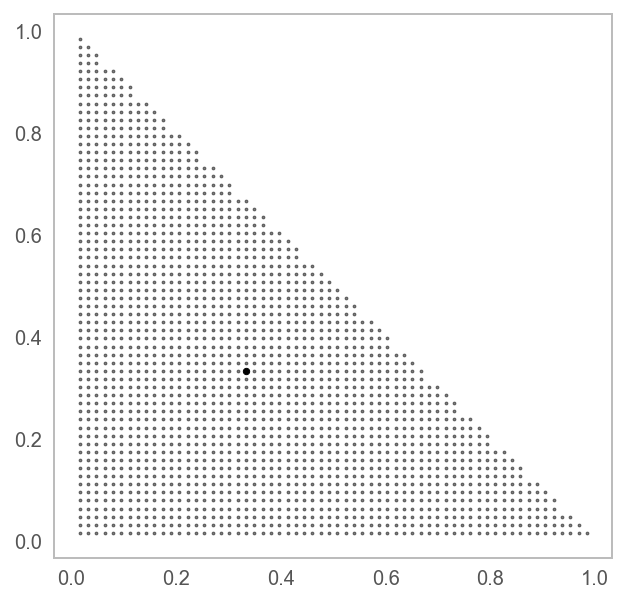

In [4]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)

P = geom.polygone([[0, 0], [0, 1], [1, 0]])
print(P.info())
P.visualize(ax)

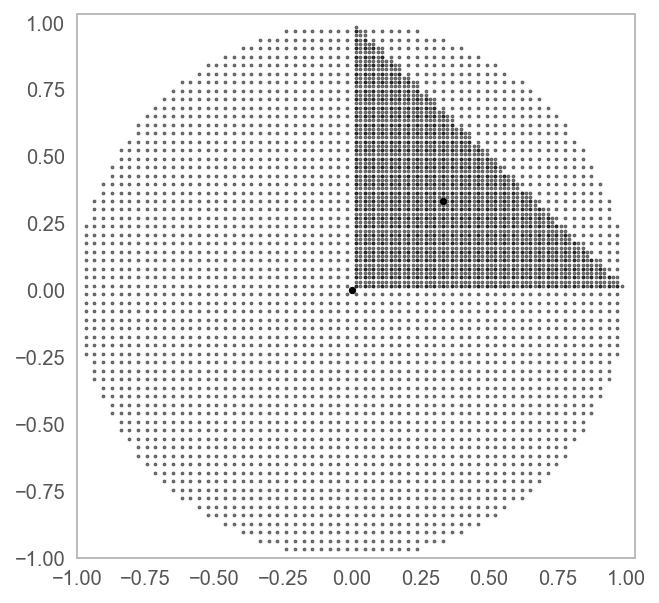

In [5]:
P = geom.polygone([[0, 0], [0, 1], [1, 0]])
D = geom.disque([0, 0], 1, "D")

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)
P.visualize(ax)
D.visualize(ax)

--------------------------------------------------------------------------------
Union U de P et de D
    L'aire de U vaut environ      3.5464
    Le centre de gravité de U est [0.09548327 0.00218367]
--------------------------------------------------------------------------------

--------------------------------------------------------------------------------
Intersection I de P et de D
    L'aire de I vaut environ      1.5724
    Le centre de gravité de I est [ 4.25517188e-01 -1.17824951e-05]
--------------------------------------------------------------------------------



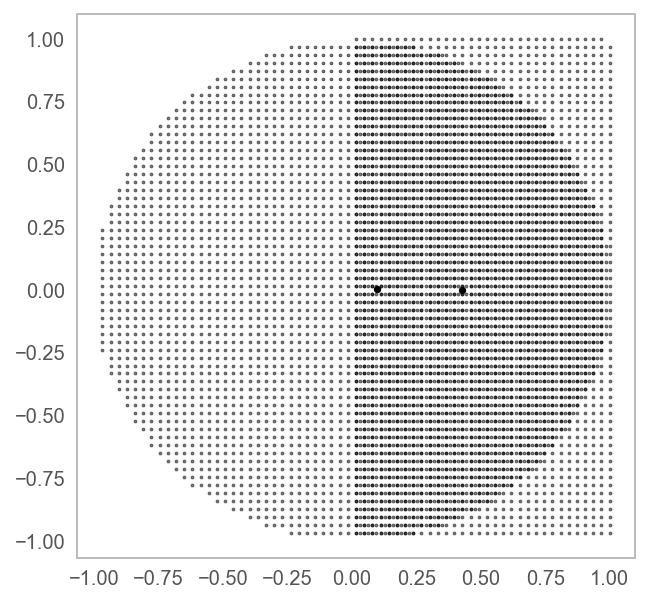

In [7]:
P = geom.polygone([[0, -1], [1, -1], [1, 1], [0, 1]], "P")
D = geom.disque([0, 0], 1, "D")
U = geom.union(P, D)
print(U.info())
I = geom.intersection(P, D)
print(I.info())
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(1, 1, 1)
ax.grid(False)
U.visualize(ax)
I.visualize(ax)

In [2]:
import TP07_geometrie as geom
help(geom.disque)

Help on class disque in module TP07_geometrie.disque:

class disque(TP07_geometrie.forme.forme)
 |  disque(c, r, nom='D')
 |  
 |  Une classe pour les disques
 |  
 |  Parameters
 |  ----------
 |  
 |  c: ndarray de taille 2
 |      le centre du disque
 |  r: float strictement positif
 |      le rayon du disque
 |  
 |  Method resolution order:
 |      disque
 |      TP07_geometrie.forme.forme
 |      abc.ABC
 |      builtins.object
 |  
 |  Methods defined here:
 |  
 |  __init__(self, c, r, nom='D')
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  info(self)
 |      renvoie des informations sur la forme géométrique
 |  
 |  ----------------------------------------------------------------------
 |  Readonly properties defined here:
 |  
 |  aire
 |      renvoie l'aire de la forme géométrique
 |  
 |  box
 |      renvoie une boite contenant la forme géométrique
 |  
 |  centre
 |  
 |  gravity
 |      renvoie le centre de gravité de la forme géométrique
